## Imports and initialization
To install the required packages, use the following command:

In [ ]:
# !pip install numpy matplotlib qiskit qiskit-machine-learning qiskit-ibm-runtime scikit-learn 

In [1]:
# Packages for synthetic data generation and pre-processing.  
from sklearn.datasets import make_blobs, make_moons
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix
import pandas as pd

# Qiskit packages
from qiskit.circuit.library import ZZFeatureMap,RealAmplitudes
from qiskit.primitives import StatevectorSampler
from qiskit_machine_learning.optimizers import SPSA
from qiskit_ibm_runtime import QiskitRuntimeService
from qiskit_ibm_runtime import SamplerV2 as Sampler
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager

# Packages for data visualization
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

In [2]:
FILE_NAME = 'Heart_Disease_and_Hospitals.csv'
df = pd.read_csv(FILE_NAME)
print(f"SUCCESS: Data loaded from {FILE_NAME}")

SUCCESS: Data loaded from Heart_Disease_and_Hospitals.csv


In [3]:
unique_sorted_states = sorted(df['state'].unique())

# Create a mapping dictionary: {'Illinois': 0, 'Iowa': 1, ...}
state_to_num = {state: i for i, state in enumerate(unique_sorted_states)}
print("State Encoding Map:")
print(state_to_num)

# Apply the mapping to the 'state' column
df['state_encoded'] = df['state'].map(state_to_num)


# --- 3. Encode 'gender' (Female=1, Male=0) ---

# Define the binary mapping
gender_map = {'Female': 1, 'Male': 0}

# Apply the mapping to the 'gender' column
df['gender_encoded'] = df['gender'].map(gender_map)

# Get unique treatments and sort them alphabetically
unique_sorted_treatments = sorted(df['treatment'].unique())

# Create a mapping dictionary for treatment
treatment_to_num = {treatment: i for i, treatment in enumerate(unique_sorted_treatments)}
print("\nTreatment Encoding Map:")
print(treatment_to_num)

# Apply the mapping to the 'treatment' column
df['treatment_encoded'] = df['treatment'].map(treatment_to_num)

State Encoding Map:
{'Alabama': 0, 'Alaska': 1, 'Arizona': 2, 'Arkansas': 3, 'California': 4, 'Colorado': 5, 'Connecticut': 6, 'Delaware': 7, 'Florida': 8, 'Georgia': 9, 'Hawaii': 10, 'Idaho': 11, 'Illinois': 12, 'Indiana': 13, 'Iowa': 14, 'Kansas': 15, 'Kentucky': 16, 'Louisiana': 17, 'Maine': 18, 'Maryland': 19, 'Massachusetts': 20, 'Michigan': 21, 'Minnesota': 22, 'Mississippi': 23, 'Missouri': 24, 'Montana': 25, 'Nebraska': 26, 'Nevada': 27, 'New Hampshire': 28, 'New Jersey': 29, 'New Mexico': 30, 'New York': 31, 'North Carolina': 32, 'North Dakota': 33, 'Ohio': 34, 'Oklahoma': 35, 'Oregon': 36, 'Pennsylvania': 37, 'Rhode Island': 38, 'South Carolina': 39, 'South Dakota': 40, 'Tennessee': 41, 'Texas': 42, 'Utah': 43, 'Vermont': 44, 'Virginia': 45, 'Washington': 46, 'West Virginia': 47, 'Wisconsin': 48, 'Wyoming': 49}

Treatment Encoding Map:
{'Counseling': 0, 'Medication': 1, 'Physiotherapy': 2, 'Rehabilitation': 3, 'Surgery': 4}


In [4]:
FEATURE_COLUMNS = ['age', 'state_encoded', 'blood_pressure', 'cholesterol', 'bmi', 'glucose_level', 'gender_encoded', 'treatment_encoded']
N_FEATURES = len(FEATURE_COLUMNS)

# X contains all selected features:
X = df[FEATURE_COLUMNS].values

# y contains the target label (HeartDisease):
y = df['heart_disease'].values

# --- 3. Print Results ---
print("\n--- Data Head ---")
print(df.head()) # Shows the first 5 rows of the loaded DataFrame

print("\n--- Array Dimensions ---")
print(f"Features (X) shape: {X.shape}")
print(f"Labels (y) shape: {y.shape}")
print("\nData is now loaded from the external CSV and is ready for QML.")


--- Data Head ---
        full_name  age country          state  blood_pressure  cholesterol  \
0   Alice Johnson   21     USA           Utah      138.068129   270.564349   
1    Bob Williams   44     USA   North Dakota      100.383639   160.910030   
2    Oliver Jones   22     USA           Iowa      145.618318   208.490251   
3     Quinn Davis   19     USA      Louisiana      152.577870   348.153738   
4  Alice Martinez   64     USA  Massachusetts      111.793570   200.628925   

         bmi  glucose_level  gender first_name last_name  \
0  36.101427      63.487954  Female      Alice   Johnson   
1  14.330471     187.008977  Female        Bob  Williams   
2  20.277098      35.903576  Female     Oliver     Jones   
3  62.712693      31.495166  Female      Quinn     Davis   
4  14.468485     154.513129  Female      Alice  Martinez   

                       hospital       treatment  \
0            Starlight Hospital   Physiotherapy   
1           Maple Leaf Hospital      Counseling  

In [5]:
# X, y = make_moons(n_samples=100, noise=0.1, random_state=42)
#X, y = make_blobs(n_samples=100, centers=2, n_features=4, cluster_std=0.1, random_state=42)

In [6]:
TEST_SIZE = 0.2  # 30% of data for testing
RANDOM_SEED = 24 # Ensures reproducibility

X_train, X_test, y_train, y_test = train_test_split(
    X, 
    y, 
    test_size=TEST_SIZE, 
    random_state=RANDOM_SEED,
    # stratify=y  # Uncomment if you want proportional split of classes
)

print("\n--- Data Splitting Results ---")
print("Data successfully split into training and testing sets.")
print(f"Total Samples: {X.shape[0]}")
print(f"Training Samples (X_train): {X_train.shape[0]}")
print(f"Testing Samples (X_test): {X_test.shape[0]}")


--- Data Splitting Results ---
Data successfully split into training and testing sets.
Total Samples: 10000
Training Samples (X_train): 8000
Testing Samples (X_test): 2000


In [7]:
train_data = X_train
test_data = X_test
train_labels = y_train
test_labels = y_test

Then, we randomly divide the data into two subsets, one for training and one for testing. The testing subset will contain 30% of the generated records and will not be part of the training process. 

## Circuit Preparation

One of the key components of the VQC method is the feature map definition, which maps data nonlinearly into a vector of the Hilbert space of density matrices $|\phi(\tilde{x})\rangle\langle\phi(\tilde{x})|$. The correct data mapping could lead to better classification performance. For our data, we will use a second-order diagonal expansion ```ZZFeatureMap```, where the number of qubits $n$ in the quantum circuit is equal to the number of features from the classical data, encoded  using coefficients $\phi_S(\mathbf{x})$, where $S \subseteq\{1, \ldots, n \}$, $|S|\leq 2$ and:

$$
\phi_S:x \mapsto \Bigg\{
\begin{array}{ll}
    x_i & \text{if } S=\{i\} \\
    (\pi-x_i)(\pi-x_j) & \text{if } S=\{i,j\}
\end{array}
$$

The variational circuit selected is ```RealAmplitudes``` that alternates layers of parametric $RY$ gates with $CNOT$, we will use 4 repetitions leading to 20 tunable parameters.

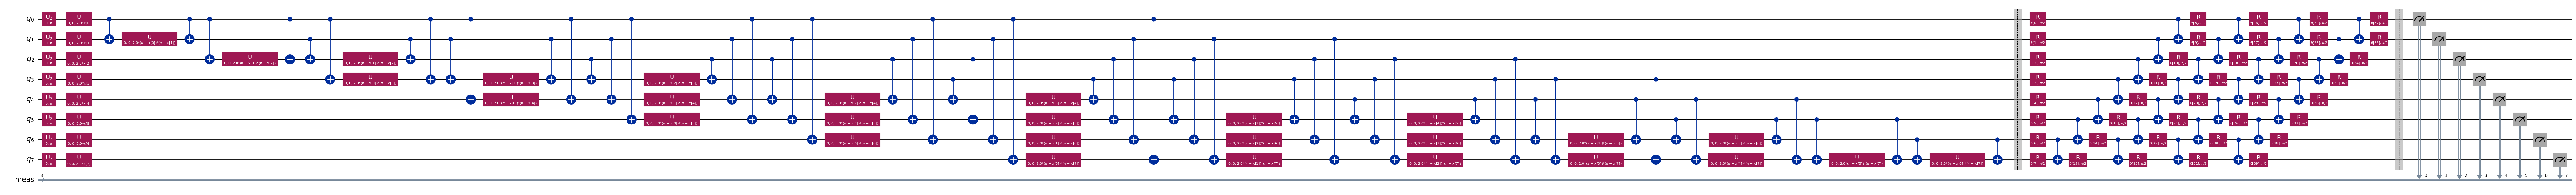

In [8]:
feature_map = ZZFeatureMap(feature_dimension=N_FEATURES, reps=1)
feature_map.barrier()
var_form = RealAmplitudes(num_qubits=N_FEATURES, reps=4)
circuit = feature_map.compose(var_form).decompose()
circuit.measure_all()
circuit.decompose().draw(output="mpl", fold=-1, style="iqp")

## VQC Training
Next, we will create the functions needed to tune the variational parameters from our quantum circuit. First, we will assign the data to the parameters of the feature map, then we will update $\tilde{\theta}$ in the variational circuit with the optimization algorithm.

In [9]:
def circuit_instance(data, variational):
    """
    Assigns parameter values to the quantum circuit.
    """
    parameters = {}
    for i, p in enumerate(feature_map.parameters):
        parameters[p] = data[i]
    for i, p in enumerate(var_form.ordered_parameters):
        parameters[p] = variational[i]
    return circuit.assign_parameters(parameters)


We need to translate the predictions obtained with the quantum circuit into probabilities. To achieve this, we evaluate the parity from the bitstrings and calculate their probability of occurrence given the number of shots from the execution. 

In [10]:
def labels_probability(results):
    """
    Converts a dictionary of bitstrings and their counts, to parities and their counts
    """
    shots = sum(results.values())
    probabilities = {0: 0, 1: 0}
    for bitstring, counts in results.items():
        label = (sum(int(k) for k in list(bitstring))+1) % 2
        probabilities[label] += counts / shots
    return probabilities

Then, we create the function ```classification_probability_simulation``` to build a quantum circuit for each data point using the variational parameters, this function runs these circuits using the IBM Qiskit Simulator and calculates the classification probabilities based on the measurement results. We use the ```cross_entropy_loss``` function to provide a measure of prediction accuracy.

In [11]:
def classification_probability_simulation(data, variational):
    """
    Classify data points using given parameters.
    """
    circuits = [circuit_instance(d, variational) for d in data]
    sampler = StatevectorSampler() # Estimator() matrix_state_product
    results = sampler.run(circuits).result()
    # print(results[1].data.meas.get_counts())
    classification = [labels_probability(results[i].data.meas.get_counts()) for i, c in enumerate(circuits)]
    return classification

In [12]:
def cross_entropy_loss(classification, expected):
    """
    Calculate accuracy of predictions using cross entropy loss.
    """
    p = classification.get(expected)  
    return -np.log(p + 1e-10)

Finally, with the``` cost_function``` we evaluate the overall performance of the quantum circuit given variational parameters on the dataset by finding the average of the cross-entropy loss across all data points, which is then used by the ```objective_function``` to minimize the cost.

In [13]:
def cost_function(data, labels, variational):
    """
    Evaluates performance of our circuit with variational parameters on data.
    """
    classifications = classification_probability_simulation(data, variational)
    cost = 0
    for i, classification in enumerate(classifications):
        cost += cross_entropy_loss(classification, labels[i])
    cost /= len(data)
    return cost


In [14]:
def objective_function(variational):
    """Cost function of circuit parameters on training data.
    The optimizer will attempt to minimize this."""
    return cost_function(train_data, train_labels, variational)


Now we are ready to run the program and obtain the variational parameters from the circuit, using the SPSA algorithm from SciPy to minimize the function.

In [ ]:
class OptimizerLog:
    """Log to store optimizer's intermediate results"""
    def __init__(self):
        self.evaluations = []
        self.parameters = []
        self.costs = []
    def update(self, evaluation, parameter, cost, _stepsize, _accept):
        """Save intermediate results. Optimizer passes five values
        but we ignore the last two."""
        self.evaluations.append(evaluation)
        self.parameters.append(parameter)
        self.costs.append(cost)
             
# Set up the optimization
log = OptimizerLog()
optimizer = SPSA(maxiter=100, callback=log.update)

initial_point = np.zeros((var_form.num_parameters))

# Run the optimization
result = optimizer.minimize(objective_function, initial_point)

opt_var = result.x
opt_value = result.fun

fig = plt.figure()
plt.plot(log.evaluations, log.costs)
plt.xlabel('Steps')
plt.ylabel('Cost')
plt.grid(True)
plt.rc('axes', linewidth=2)  # Set the axes linewidth globally
ax = plt.gca()  # Get current axes
ax.spines['top'].set_linewidth(2)
ax.spines['right'].set_linewidth(2)
ax.spines['bottom'].set_linewidth(2)
ax.spines['left'].set_linewidth(2)
plt.show()

## Model Test

Now that the model is trained, we will evaluate its performance using the test subset we isolated at the beginning. We will conduct three experiments: 
*	**Simulator Test:** We will test the model using the simulator, which will provide information about the model in a noiseless environment and serve as the baseline to evaluate the performance of the executions using real devices.
*	**Qiskit Test:** We will test the model executing the inference circuits on a real device to assess the noise and decoherence effect in the model.


In [ ]:
def create_conf_mat(y_true, y_pred, title):
    # Compute confusion matrix
    cm = confusion_matrix(y_true, y_pred)

    # Normalize the confusion matrix by row (i.e., by the number of samples in each class)
    cm_normalized = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis] * 100

    # Create a custom colormap
    colors = [(1, 1, 1), (0/255, 255/255, 0/255)] 
    n_bins = 100  # Number of bins in the colormap
    cmap_name = 'custom_blue'
    custom_cmap = LinearSegmentedColormap.from_list(cmap_name, colors, N=n_bins)

    # Display confusion matrix
    fig, ax = plt.subplots()
    cax = ax.matshow(cm_normalized, cmap=custom_cmap)

    # Add color bar
    fig.colorbar(cax)

    # Set predefined RGB color for the text
    for i in range(cm_normalized.shape[0]):
        for j in range(cm_normalized.shape[1]):
            color = 'white' if i == j else 'black'
            ax.text(j, i, f'{cm_normalized[i, j]:.1f}%', va='center', ha='center', color=color)

    # Set predefined background color for the diagonal elements (e.g., RGB (255, 255, 0))
    diagonal_color = (98/255, 35/255, 223/255)  # Normalize to 0-1 range
    for i in range(cm_normalized.shape[0]):
        ax.add_patch(plt.Rectangle((i-0.5, i-0.5), 1, 1, fill=True, color=diagonal_color, alpha=0.3))

    # Set predefined background color for the plot (e.g., RGB (240, 240, 240))
    background_color = (1, 1, 1)  # Normalize to 0-1 range
    fig.patch.set_facecolor(background_color)
    ax.set_facecolor(background_color)

    plt.title(title)
    plt.xlabel('Predicted label')
    plt.ylabel('True label')
    plt.show()

### Simulator Test

In [ ]:
def test_classifier(data, labels, variational):
    """
    Gets classifier'spredictions and calculates accuracy 
    """
    probability = classification_probability_simulation(data, variational)
    predictions = [0 if p[0] >= p[1] else 1 for p in probability]
    accuracy = 0
    for i, prediction in enumerate(predictions):
        if prediction == labels[i]:
            accuracy += 1
    accuracy /= len(labels)
    print(f"Simulated Test Accuracy: {accuracy * 100:.2f}%")
    create_conf_mat(labels, predictions, "Simulated Evaluation")
    return accuracy, predictions

accuracy_sim, predictions_sim = test_classifier(test_data, test_labels, opt_var)


### Using real devices

For running on a real device we need to provide the account information, in this example we are using [IBM Quantum](https://quantum.ibm.com/) hardware, then we need to define the hub, group, project and token. When using Fire Opal you also need to provide your [credentials](https://accounts.q-ctrl.com/), and it will execute the circuits on your behalf.

In [48]:
from qiskit_ibm_runtime import QiskitRuntimeService

service = QiskitRuntimeService(name='Paul')

management.get:WARNING:2025-11-19 21:05:17,131: Loading saved account: Paul


Next, we will search for the least busy device to execute our circuits

In [49]:
backend = service.backend("ibm_torino")

backend

<IBMBackend('ibm_torino')>

### Qiskit Test

When using real devices, we must modify some functions to execute the circuits and collect the information. We need to change the Sampler function to define the hardware backend we will use, and we need to rewrite the circuit to match the topology from this backend in a process known as [transpilation](https://docs.quantum.ibm.com/api/qiskit/transpiler). 

In [50]:
sampler = Sampler(backend)
pm = generate_preset_pass_manager(optimization_level=3, backend=backend)

In [51]:
def classification_probability_qiskit(data, variational):
    """
    Classify data points using given parameters.
    """
    circuits = [circuit_instance(d, variational) for d in data]
    isa_circuit = pm.run(circuits)
    results = sampler.run(isa_circuit, shots=1024).result()
    classification = [
        labels_probability(i['__value__']['data'].meas.get_counts()) for i in results]
    return classification

In [52]:
def test_classifier(data, labels, variational):
    """
    Gets classifier'spredictions and calculates accuracy 
    """
    probability = classification_probability_qiskit(data, variational)
    predictions = [0 if p[0] >= p[1] else 1 for p in probability]
    accuracy = 0
    for i, prediction in enumerate(predictions):
        if prediction == labels[i]:
            accuracy += 1
    accuracy /= len(labels)
    print(f"Qiskit Test Accuracy: {accuracy * 100:.2f}%")
    create_conf_mat(labels, predictions, "Qiskit Evaluation")
    return accuracy, predictions

accuracy_qiskit, predictions_qiskit = test_classifier(test_data, test_labels, opt_var)

TypeError: 'SamplerPubResult' object is not subscriptable

Qiskit Test Accuracy (Aer Sim): 90.00%


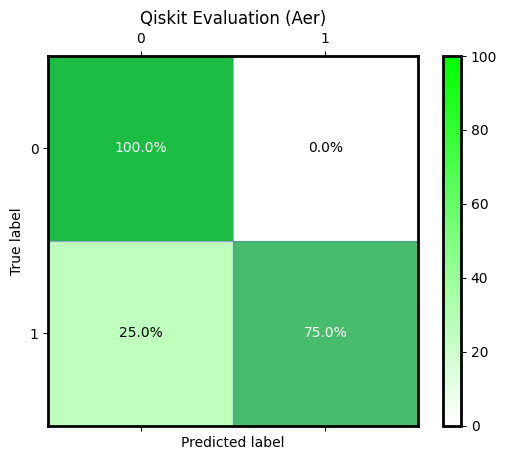

In [53]:
from qiskit_aer import AerSimulator
from qiskit import QuantumCircuit

# --- Local Aer Simulator ---
simulator = AerSimulator()

# Optional: Use fake Torino with real noise
# from qiskit.providers.fake_provider import FakeTorino
# simulator = AerSimulator.from_backend(FakeTorino())

def classification_probability_qiskit(data, variational):
    circuits = [circuit_instance(d, variational) for d in data]
    
    # Run all circuits on Aer
    job = simulator.run(circuits, shots=1024)
    result = job.result()
    
    # Extract counts
    classification = []
    for counts in result.get_counts():
        prob = labels_probability(counts)
        classification.append(prob)
    
    return classification


def test_classifier(data, labels, variational):
    probability = classification_probability_qiskit(data, variational)
    predictions = [0 if p[0] >= p[1] else 1 for p in probability]
    accuracy = sum(1 for pred, true in zip(predictions, labels) if pred == true) / len(labels)
    
    print(f"Qiskit Test Accuracy (Aer Sim): {accuracy * 100:.2f}%")
    create_conf_mat(labels, predictions, "Qiskit Evaluation (Aer)")
    return accuracy, predictions


# --- Run the test ---
accuracy_qiskit, predictions_qiskit = test_classifier(test_data, test_labels, opt_var)

management.get:WARNING:2025-11-19 21:06:22,627: Loading saved account: Paul


Connected to ibm_torino | Qubits: 133
Pending jobs: 0
Ready for quantum execution (job mode).

Starting REAL quantum execution (job mode)...

Building 20 circuits...
Transpiling for ibm_torino...
Submitting 20 circuits (1024 shots each)...
Job ID: d4f7f9ccdebc73evqkgg | Status: QUEUED
Waiting for quantum results...
Processing results...
  Circuit 0: {'0100': 190, '1000': 65, '0010': 113, '1101': 231, '0001': 123, '1011': 42, '0011': 44, '1001': 20, '0111': 55, '0000': 25, '0101': 23, '1100': 27, '1110': 23, '1111': 9, '0110': 14, '1010': 20} → {0: 0.822265625, 1: 0.177734375}
  Circuit 1: {'1110': 16, '0111': 56, '0110': 60, '0010': 272, '0101': 45, '1101': 90, '0011': 68, '1010': 25, '0100': 174, '1011': 70, '0000': 54, '1111': 27, '1100': 23, '0001': 17, '1001': 13, '1000': 14} → {0: 0.6923828125, 1: 0.3076171875}
  Circuit 2: {'1000': 202, '1110': 98, '0000': 5, '0111': 71, '0011': 64, '1101': 119, '0010': 78, '0100': 52, '0001': 129, '1100': 53, '0110': 44, '1001': 22, '1010': 16, 

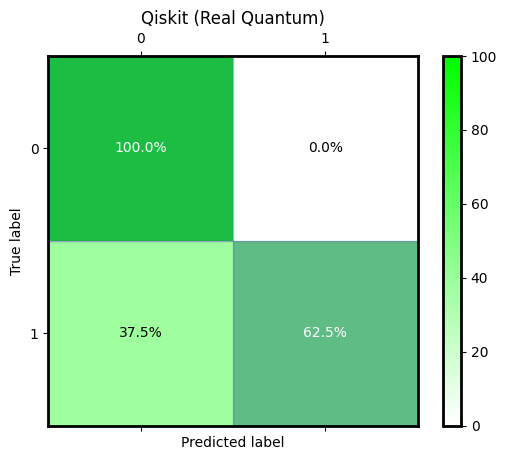

Quantum run complete.


In [54]:
from qiskit_ibm_runtime import QiskitRuntimeService, SamplerV2 as Sampler
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager

# === Connect to IBM Quantum (Free Tier) ===
service = QiskitRuntimeService(name='Paul')
backend = service.backend("ibm_torino")

print(f"Connected to {backend.name} | Qubits: {backend.num_qubits}")
print(f"Pending jobs: {len(service.jobs(pending=True))}")

# === V2: Job Mode (No Session) ===
sampler = Sampler(mode=backend)  # ← Job mode for free tier
pm = generate_preset_pass_manager(optimization_level=3, backend=backend)

print("Ready for quantum execution (job mode).")


def classification_probability_qiskit(data, variational):
    """
    Runs on REAL ibm_torino (job mode, V2).
    """
    print(f"Building {len(data)} circuits...")
    circuits = [circuit_instance(d, variational) for d in data]
    
    print("Transpiling for ibm_torino...")
    isa_circuits = pm.run(circuits)

    print(f"Submitting {len(isa_circuits)} circuits (1024 shots each)...")
    job = sampler.run(pubs=isa_circuits, shots=1024)
    print(f"Job ID: {job.job_id()} | Status: {job.status()}")

    print("Waiting for quantum results...")
    result = job.result()  # Blocks until done

    print("Processing results...")
    classification = []
    for i, pub_result in enumerate(result):
        counts = pub_result.data.meas.get_counts()
        prob = labels_probability(counts)
        classification.append(prob)
        if i < 3:
            print(f"  Circuit {i}: {counts} → {prob}")

    return classification


def test_classifier(data, labels, variational):
    """
    Full test on real quantum hardware.
    """
    prob = classification_probability_qiskit(data, variational)
    predictions = [0 if p[0] >= p[1] else 1 for p in prob]
    accuracy = sum(p == t for p, t in zip(predictions, labels)) / len(labels)
    
    print(f"\nFINAL ACCURACY ON ibm_torino: {accuracy * 100:.2f}%")
    create_conf_mat(labels, predictions, "Qiskit (Real Quantum)")
    
    return accuracy, predictions


# === RUN ON REAL QUANTUM ===
print("\nStarting REAL quantum execution (job mode)...\n")
accuracy_qiskit, predictions_qiskit = test_classifier(test_data, test_labels, opt_var)

print("Quantum run complete.")